In [30]:
!git clone https://github.com/qishenzhou/MMTD.git

Cloning into 'MMTD'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 50 (delta 17), reused 46 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 1.02 MiB | 1.44 MiB/s, done.
Resolving deltas: 100% (17/17), done.


In [31]:
%cd MMTD

/home/aadiuntu/MMTD/Graph-WaveNet/MMTD


In [32]:
pwd

'/home/aadiuntu/MMTD/Graph-WaveNet/MMTD'

In [33]:
# MOVE FILES INTO data/mmtd
# mv "/mnt/d/C Drive Data/Downloads/distance_matrix.h5" ~/MMTD/data/mmtd/distance_matrix.h5


In [34]:
!python -m pip install -r requirements.txt

In [53]:
%cd ..

/home/aadiuntu/MMTD


In [54]:
!python -m examples.load_fixed_sensor --data-root ./data

/home/aadiuntu/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
DataBatch(x=[556, 16, 3], edge_index=[2, 7684], edge_attr=[7684], y=[556, 16, 1], pos=[556, 16, 2], t_id=[2, 278], n_id=[556], time_enc=[556, 16, 3], static_aux=[556, 16, 12], poi_aux=[556, 16, 10], label_unobs_mask=[556], graph_mask=[556], num_nodes=556, batch=[556], ptr=[3])
x: (556, 16, 3) y: (556, 16, 1)
Unobserved nodes: 50
Target values in original units: (556, 16, 1)


In [55]:
!git clone https://github.com/nnzhan/Graph-WaveNet.git

fatal: destination path 'Graph-WaveNet' already exists and is not an empty directory.


In [56]:
%cd Graph-WaveNet

/home/aadiuntu/MMTD/Graph-WaveNet


In [57]:
!pip install torch numpy pandas h5py scipy scikit-learn

### Prepare MMTD data

In [81]:

import os
import h5py
import numpy as np

DATA_DIR = "/data/mmtd"
OUTPUT_DIR = os.path.join(DATA_DIR, "processed")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# use past 3 hours for prediction - 12 exp * 15 min = 180 min
SEQ_LEN = 12
# try with 256 nodes
MAX_NODES = 256
# predict feature 2 which is congestion level
TARGET_FEATURE = 2

# Load HDF5
with h5py.File(os.path.join(DATA_DIR, "fixed_sensor_data.h5"), "r") as f:
    # traffic observations
    values = f["data/values"][:].astype(np.float32)

    # feature names
    features = [
        x.decode() if isinstance(x, bytes) else str(x)
        for x in f["metadata/features"][:]
    ]

    # ids of traffic sensors
    node_ids = f["metadata/nodes"][:]

print("Original shape:", values.shape)
print("Features:", features)
print("Node IDs:", len(node_ids))

# Select only 256 nodes but every timestamp and feature
if MAX_NODES is not None:
    values = values[:, :MAX_NODES, :]
    node_ids = node_ids[:MAX_NODES]

# Timestamp, Node, Features
T, N, F = values.shape


Original shape: (2976, 2780, 3)
Features: ['volume', 'occ', 'conges_levl']
Node IDs: 2780


### Preprocessing

In [82]:
# 70% training, 10% val, 20% test
train_end = int(T * 0.70)
val_end = int(T * 0.80)

# Replace missing values using per-sensor and feature means axis = 0 takes mean over timestamps
training_means = np.nanmean(values[:train_end], axis=0)
# If an entire node + features is missing, use the global feature mean
global_means = np.nanmean(values[:train_end], axis=(0, 1))

for j in range(F):
    bad_means = ~np.isfinite(training_means[:, j])
    training_means[bad_means, j] = global_means[j]

for j in range(F):
    bad = ~np.isfinite(values[:, :, j])
    values[:, :, j] = np.where(
        bad,
        training_means[:, j][None, :],
        values[:, :, j]
    )

In [84]:
mean = values[:train_end].mean(axis=0)
std = values[:train_end].std(axis=0)
std[std < 1e-6] = 1.0

normalized = (values - mean[None, :, :]) / std[None, :, :]

# Create sliding windows
# X: (samples, time, nodes, features)
# (T = 2976-12, 12, 256, 3)
X = np.stack([
    normalized[i:i + SEQ_LEN]
    for i in range(T - SEQ_LEN)
])

# y: congestion, shape (samples, 1, nodes)
# because 1 output feature - (2976-12, 1, 256)
y = normalized[SEQ_LEN:, :, TARGET_FEATURE][:, None, :]

# Split according to target timestamps
train_count = train_end - SEQ_LEN
val_count = val_end - train_end

splits = {
    "train": (X[:train_count], y[:train_count]),
    "valid": (
        X[train_count:train_count + val_count],
        y[train_count:train_count + val_count]
    ),
    "test": (
        X[train_count + val_count:],
        y[train_count + val_count:]
    )
}

for name, (x, target) in splits.items():
    path = os.path.join(OUTPUT_DIR, f"{name}.npz")
    np.savez_compressed(path, x=x, y=target)
    print(name, x.shape, target.shape, "->", path)

# save preprocessed data
np.savez(
    os.path.join(OUTPUT_DIR, "scaler.npz"),
    mean=mean,
    std=std,
    node_ids=node_ids
)

train (2071, 12, 256, 3) (2071, 1, 256) -> /data/mmtd/processed/train.npz
valid (297, 12, 256, 3) (297, 1, 256) -> /data/mmtd/processed/valid.npz
test (596, 12, 256, 3) (596, 1, 256) -> /data/mmtd/processed/test.npz


### Load processed datasets

In [85]:
import torch
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_split(name):
    data = np.load(os.path.join(OUTPUT_DIR, f"{name}.npz"))

    x = torch.from_numpy(data["x"].astype(np.float32))
    y = torch.from_numpy(data["y"].astype(np.float32))

    # combine x and y into one DS
    return TensorDataset(x, y)

train_dataset = load_split("train")
val_dataset = load_split("valid")
test_dataset = load_split("test")

BATCH_SIZE = 4

# helps load data as batches
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=(device.type == "cuda")
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 518
Validation batches: 75
Testing batches: 149


### Create NN


In [ ]:
import sys

sys.path.insert(0, "/content/Graph-WaveNet")

from model import gwnet

# can be changed
# size of temporal convolution filter - compares 2 time positions
# block: group of temporal processing layers.
# dilation_channels : related ti time series relations
# residual_channels : 3 feat internally processed as 8 channels
# aptinit: adaptive adjacency initialisation, dont init addadj
# addaptadj: adaptive adjacency mechanism - learns relationships between nodes
# gcn_bool: allows graph convolution - allows info across nodes to influence each other
# supports: No predefined adjacency matrix, we learn it
# dropout : regularization, 10% of activations dropped during training to prevent overfitting
model = gwnet(
    device=device,
    num_nodes=NUM_NODES,
    dropout=0.1,
    supports=None,
    gcn_bool=True,
    addaptadj=True,
    aptinit=None,
    in_dim=3,
    out_dim=1,
    residual_channels=8,
    dilation_channels=8,
    skip_channels=32,
    end_channels=64,
    kernel_size=2,
    blocks=2,
    layers=2
).to(device)

print("Model initialized!")
print("Parameters:", sum(p.numel() for p in model.parameters()))

Model initialized!
Parameters: 10721


### Run input on Model

In [69]:
X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

# (B, T, N, F) -> (B, F, N, T) <- WaveNet exepects this form
X_batch = X_batch.permute(0, 3, 2, 1).contiguous()

# dont track gradients but check the model
with torch.no_grad():
    output = model(X_batch)

print("Input:", X_batch.shape)
print("Target:", y_batch.shape)
print("Output:", output.shape)

Input: torch.Size([4, 3, 256, 12])
Target: torch.Size([4, 1, 256])
Output: torch.Size([4, 1, 256, 6])


### Train Model

In [87]:
import torch
import torch.nn.functional as F
import torch.optim as optim
from pathlib import Path

# Set up optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Set up checkpoint in a pytorch model file
checkpoint_path = Path("checkpoints/gwnet_mmtd_best.pth")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

best_val_loss = float("inf")

# Train the model
EPOCHS = 10

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0

    for x, y in train_loader:

        x = x.to(device)
        y = y.to(device)

        # Rearrange input for Graph WaveNet
        x = x.permute(0, 3, 2, 1).contiguous()

        # Predict
        optimizer.zero_grad()
        prediction = model(x)
        prediction = prediction[:, :, :, -1]

        # Calculate error - MAE
        loss = F.l1_loss(prediction, y)

        # Learn from the error - backpropagation
        loss.backward()
        optimizer.step()

        # total batch loss
        train_loss += loss.item() * x.size(0)

    # average loss
    train_loss /= len(train_loader.dataset)

    # validation
    model.eval()
    val_loss = 0

   # dont compute gradients and dont update weights since its val
    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(device)
            y = y.to(device)

            x = x.permute(0, 3, 2, 1).contiguous()

            prediction = model(x)
            prediction = prediction[:, :, :, -1]

            loss = F.l1_loss(prediction, y)
            val_loss += loss.item() * x.size(0)

    val_loss /= len(val_loader.dataset)

    # results
    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train MAE: {train_loss:.4f} | "
        f"Val MAE: {val_loss:.4f}"
    )

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), checkpoint_path)

print("\nTraining complete!")
print("Best validation MAE:", best_val_loss)
print("Saved model:", checkpoint_path)


Epoch 1/10 | Train MAE: 0.3788 | Val MAE: 0.3113
Epoch 2/10 | Train MAE: 0.3267 | Val MAE: 0.3012
Epoch 3/10 | Train MAE: 0.3207 | Val MAE: 0.3032
Epoch 4/10 | Train MAE: 0.3181 | Val MAE: 0.3021
Epoch 5/10 | Train MAE: 0.3158 | Val MAE: 0.2986
Epoch 6/10 | Train MAE: 0.3150 | Val MAE: 0.2960
Epoch 7/10 | Train MAE: 0.3136 | Val MAE: 0.2975
Epoch 8/10 | Train MAE: 0.3131 | Val MAE: 0.2955
Epoch 9/10 | Train MAE: 0.3137 | Val MAE: 0.2951
Epoch 10/10 | Train MAE: 0.3118 | Val MAE: 0.2952

Training complete!
Best validation MAE: 0.2950554215145432
Saved model: checkpoints/gwnet_mmtd_best.pth


### Plot training and validation error

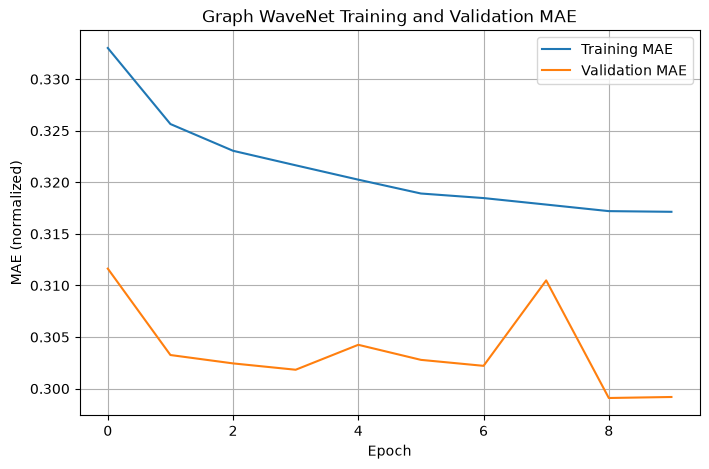

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history["train"], label="Training MAE")
plt.plot(history["validation"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (normalized)")
plt.title("Graph WaveNet Training and Validation MAE")
plt.legend()
plt.grid(True)
plt.show()

Validation error better than training funnily

In [91]:
# Load trained model
model.load_state_dict(
    torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
)
# eval mode
model.eval()

# Load normalization values
scaler = np.load(Path(OUTPUT_DIR) / "scaler.npz")

target_mean = torch.tensor(
    scaler["mean"][:, TARGET_FEATURE], dtype=torch.float32, device=device
).view(1, 1, NUM_NODES)

target_std = torch.tensor(
    scaler["std"][:, TARGET_FEATURE], dtype=torch.float32, device=device
).view(1, 1, NUM_NODES)


In [92]:
# persistence = congestion stays same
all_predictions = []
all_targets = []
all_baseline = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)

        # Model input
        model_input = x.permute(0, 3, 2, 1).contiguous()

        output = model(model_input)
        prediction = output[:, :, :, -1]

        # Persistence - last observed congestion
        baseline = x[:, -1, :, TARGET_FEATURE].unsqueeze(1)

        all_predictions.append(prediction)
        all_targets.append(y)
        all_baseline.append(baseline)

# concatenate all batch predictions
predictions = torch.cat(all_predictions, dim=0)
targets = torch.cat(all_targets, dim=0)
baseline = torch.cat(all_baseline, dim=0)

# Convert normalized values back to original units
predictions_real = predictions * target_std + target_mean
targets_real = targets * target_std + target_mean
baseline_real = baseline * target_std + target_mean

model_mae = torch.mean(torch.abs(predictions_real - targets_real)).item()

baseline_mae = torch.mean(torch.abs(baseline_real - targets_real)).item()

print(f"Graph WaveNet Test MAE: {model_mae:.5f}")
print(f"Persistence Test MAE:   {baseline_mae:.5f}")

Graph WaveNet Test MAE: 2.06134
Persistence Test MAE:   2.53823


In [93]:
# save results
import json
from pathlib import Path

results = {
    "nodes": NUM_NODES,
    "input_features": features,
    "target": features[TARGET_FEATURE],
    "sequence_length": SEQ_LEN,
    "prediction_interval": "15 minutes",
    "graph_wavenet_test_mae": model_mae,
    "persistence_test_mae": baseline_mae,
    "best_validation_loss": best_val_loss
}

# Create results directory automatically
RESULTS_DIR = Path.cwd() / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save JSON file
RESULTS_PATH = RESULTS_DIR / "gwnet_mmtd_results.json"

with open(RESULTS_PATH, "w") as f:
    json.dump(results, f, indent=4)

print(json.dumps(results, indent=4))
print("\nResults saved to:", RESULTS_PATH)

{
    "nodes": 256,
    "input_features": [
        "volume",
        "occ",
        "conges_levl"
    ],
    "target": "conges_levl",
    "sequence_length": 12,
    "prediction_interval": "15 minutes",
    "graph_wavenet_test_mae": 2.0613420009613037,
    "persistence_test_mae": 2.5382349491119385,
    "best_validation_loss": 0.2950554215145432
}

Results saved to: /home/aadiuntu/MMTD/Graph-WaveNet/results/gwnet_mmtd_results.json


In [80]:
# TO DO - Check for road length in dataset - transform congestion into travel time with road length